In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
mnist = fetch_openml('mnist_784', as_frame=False, parser="auto")

In [55]:
X=mnist.data
y = mnist.target.astype(np.int32)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=20000,random_state=42)
X_train,X_val,y_train,y_val=train_test_split(X_train,y_train,test_size=10000,random_state=42)

In [56]:
print(len(X_train),len(X_val),len(X_test))

40000 10000 20000


In [57]:
X_train = X_train / 255.0
X_val = X_val / 255.0
X_test = X_test / 255.0

In [58]:
X_train = X_train.reshape(-1, 28, 28)
X_val = X_val.reshape(-1, 28, 28)
X_test = X_test.reshape(-1, 28, 28)

In [59]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28,28]),
    tf.keras.layers.Dense(300, activation="relu"),
    tf.keras.layers.Dense(100, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")])

In [60]:
tf.keras.backend.clear_session()
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 784)               0         
                                                                 
 dense (Dense)               (None, 300)               235500    
                                                                 
 dense_1 (Dense)             (None, 100)               30100     
                                                                 
 dense_2 (Dense)             (None, 10)                1010      
                                                                 
Total params: 266610 (1.02 MB)
Trainable params: 266610 (1.02 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [61]:
model.compile(loss=tf.keras.losses.sparse_categorical_crossentropy,
              optimizer=tf.keras.optimizers.SGD(),
              metrics=[tf.keras.metrics.sparse_categorical_accuracy])

In [62]:
history = model.fit(X_train, y_train,
                    epochs=30,
                    validation_data=(X_val, y_val),
                    batch_size=128)

Epoch 1/30
313/313 [==============================] - 1s 3ms/step - loss: 1.3613 - sparse_categorical_accuracy: 0.6801 - val_loss: 0.7272 - val_sparse_categorical_accuracy: 0.8344
Epoch 2/30
313/313 [==============================] - 1s 2ms/step - loss: 0.5736 - sparse_categorical_accuracy: 0.8594 - val_loss: 0.4705 - val_sparse_categorical_accuracy: 0.8769
Epoch 3/30
313/313 [==============================] - 1s 3ms/step - loss: 0.4311 - sparse_categorical_accuracy: 0.8849 - val_loss: 0.3904 - val_sparse_categorical_accuracy: 0.8935
Epoch 4/30
313/313 [==============================] - 1s 3ms/step - loss: 0.3730 - sparse_categorical_accuracy: 0.8979 - val_loss: 0.3474 - val_sparse_categorical_accuracy: 0.9038
Epoch 5/30
313/313 [==============================] - 1s 3ms/step - loss: 0.3393 - sparse_categorical_accuracy: 0.9049 - val_loss: 0.3202 - val_sparse_categorical_accuracy: 0.9071
Epoch 6/30
313/313 [==============================] - 1s 2ms/step - loss: 0.3156 - sparse_categorica

In [53]:
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f'\nTest accuracy: {test_acc:.4f}')

625/625 [==============================] - 1s 1ms/step - loss: 0.1664 - sparse_categorical_accuracy: 0.9532

Test accuracy: 0.9532


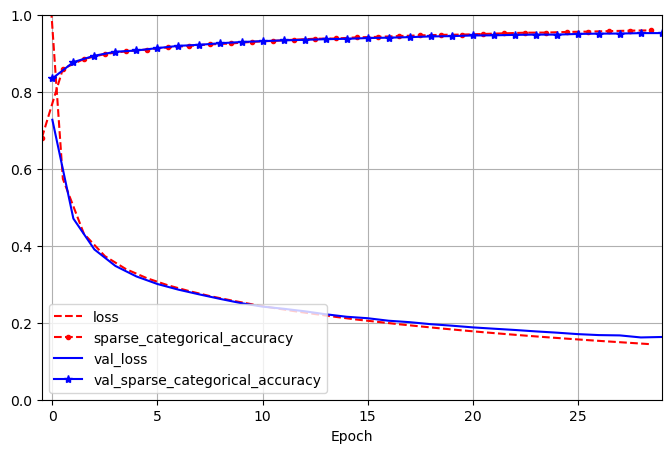

In [63]:
plt.figure(figsize=(8, 5))
for key, style in zip(history.history, ["r--", "r--.", "b-", "b-*"]):
    epochs = np.array(history.epoch) + (0 if key.startswith("val_") else -0.5)
    plt.plot(epochs, history.history[key], style, label=key)
plt.xlabel("Epoch")
plt.axis([-0.5, 29, 0., 1])
plt.legend(loc="lower left")
plt.grid()
plt.show()